In [1]:
!pip install numba

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------------------ --------------------- 1.3/2.8 MB 10.7 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 12.9 MB/s  0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   -- ------------------------------------- 2.9/41.9 MB 38.8 MB/s eta 0:00:02
   ----- ---------------------------------- 6.0/41.9 MB 19.9 MB/s eta 0:00:02
   ---------- ----------------------------- 10.7/41.9 MB 21.8 MB/s eta 0:00:02
   ------------- -------------------------- 13.6/41.9 MB 21.1 MB/s eta 0:00:02
   -------------------- ------------------- 21.0/41.9 MB 21.4 MB/s eta 0:00:01
   ----------------------- ---------------- 24.6/41.9 MB 21.3 MB/s eta 0:00:01
   ------------------------- -------------- 27.0/41.9 MB 20.7 MB/s eta 0:00:01
   ------------------------------ --------- 32.2/41.9 MB 19.9 MB/s eta 0:00:01
   ----------------------------------- ---- 36.7/41.9 MB 20.1 MB/s eta 0:00:01
 


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

np.random.seed(42)
rng = np.random.default_rng()

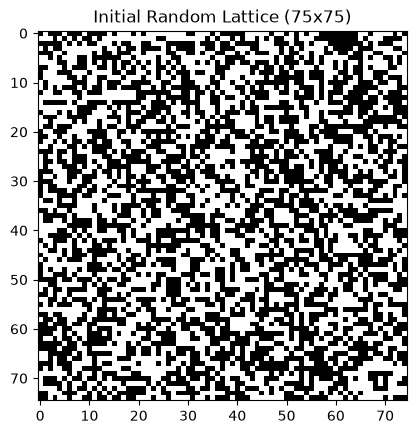

In [2]:
def initialise_grid(N):
    return np.random.choice([-1, 1], size=(N, N))

# Define grid size and test the visualization
N = 75
grid = initialise_grid(N)

plt.imshow(grid, cmap='grey')
plt.title(f"Initial Random Lattice ({N}x{N})")
plt.show()

In [3]:
@njit
def energy_local(grid, x, y, J=1.0):
    N = grid.shape[0]
    spin = grid [x, y] #pulls value of spin at coordinate (x,y)

    #finding value of spin at 4 nearest neighbours
    up_neighbour = grid[(x-1) % N, y]
    down_neighbour = grid[(x+1) % N, y]
    left_neighbour = grid[x, (y-1) % N]
    right_neighbour = grid[x, (y+1) % N]

    #summing the values of spin of 4 nearest neighbours
    neighbour_sum = up_neighbour + down_neighbour + left_neighbour + right_neighbour

    #calculates local energy at (x,y)
    local_energy = -1*J*spin*neighbour_sum
    return local_energy

In [4]:
@njit
def total_magnetisation(grid):
    return np.sum(grid)

In [5]:
@njit
def total_energy(grid):
    total = 0
    N=grid.shape[0]
    for n in range(N):
        for m in range(N):
            total += energy_local(grid, n, m, J=1.0)
    return total/2

In [6]:
@njit
def full_sweep(grid, T_values, N):
    final_magnetisation=[]
    final_energy=[]
    for T in T_values:
        for j in range(0,10000): # run 10000 times to reach equilibrium
            for i in range(0, N**2): #perform 1 monte carlo sweep
                coordinate=np.random.randint(0,N,size=2) #generate a random coordinate
                current_energy=energy_local(grid, coordinate[0], coordinate[1], J=1.0) #find current energy
                delta_E=-2*current_energy #calculate change in energy
                if delta_E<=0:
                    grid[coordinate[0], coordinate[1]] *= -1 #always allow flips that decrease the total energy
                elif delta_E>0:
                    P=np.exp(-delta_E/T) #calculate probability of allowing flip
                    r = np.random.random_sample()
                    if r<P:
                        grid[coordinate[0], coordinate[1]] *= -1
        magnetisation_list = np.zeros(10000)
        energy_list = np.zeros(10000)
        for j in range(0,10000):
            for i in range(0, N**2): #perform 1 monte carlo sweep
                coordinate=np.random.randint(0,N,size=2) #generate a random coordinate
                current_energy=energy_local(grid, coordinate[0], coordinate[1], J=1.0) #find current energy
                delta_E=-2*current_energy #calculate change in energy
                if delta_E<=0:
                    grid[coordinate[0], coordinate[1]] *= -1 #always allow flips that decrease the total energy
                elif delta_E>0:
                    P=np.exp(-delta_E/T) #calculate probability of allowing flip
                    r = np.random.random_sample()
                    if r<P:
                        grid[coordinate[0], coordinate[1]] *= -1
            magnetisation_list[j] = total_magnetisation(grid)/N**2
            energy_list[j] = total_energy(grid)/N**2
        print(T)
        av_magnet = np.mean(np.abs(magnetisation_list))
        av_energy = np.mean(energy_list)
        final_magnetisation.append(av_magnet)
        final_energy.append(av_energy)
    return final_magnetisation, final_energy

T_values = np.linspace(1.0,3.5, 150)

final_mag, final_eng = full_sweep(grid, T_values, N)

np.save('saved_magnetisation.npy', final_mag)
np.save('saved_energy.npy', final_eng)
print("done")

1.0
1.016778523489933
1.0335570469798658
1.0503355704697988
1.0671140939597314
1.0838926174496644
1.1006711409395973
1.1174496644295302
1.1342281879194631
1.151006711409396
1.167785234899329
1.1845637583892619
1.2013422818791946
1.2181208053691275
1.2348993288590604
1.2516778523489933
1.2684563758389262
1.285234899328859
1.302013422818792
1.3187919463087248
1.3355704697986577
1.3523489932885906
1.3691275167785235
1.3859060402684564
1.4026845637583891
1.4194630872483223
1.436241610738255
1.4530201342281879
1.4697986577181208
1.4865771812080537
1.5033557046979866
1.5201342281879193
1.5369127516778525
1.5536912751677852
1.570469798657718
1.587248322147651
1.604026845637584
1.6208053691275168
1.6375838926174495
1.6543624161073827
1.6711409395973154
1.6879194630872483
1.7046979865771812
1.721476510067114
1.738255033557047
1.7550335570469797
1.7718120805369129
1.7885906040268456
1.8053691275167785
1.8221476510067114
1.8389261744966443
1.8557046979865772
1.87248322147651
1.889261744966443
1.9

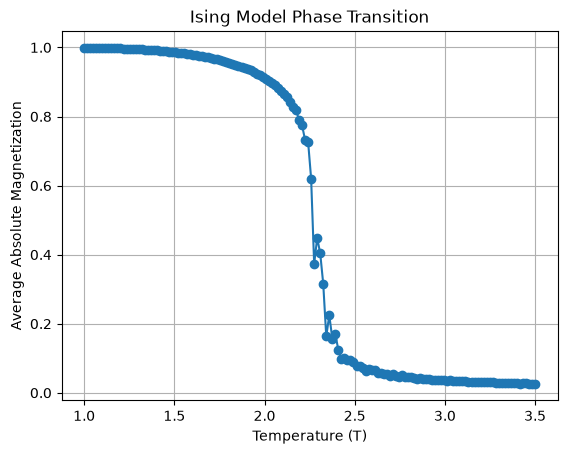

In [7]:
plt.plot(T_values, final_mag, marker='o')
plt.xlabel('Temperature (T)')
plt.ylabel('Average Absolute Magnetization')
plt.title('Ising Model Phase Transition')
plt.grid(True)
plt.show()

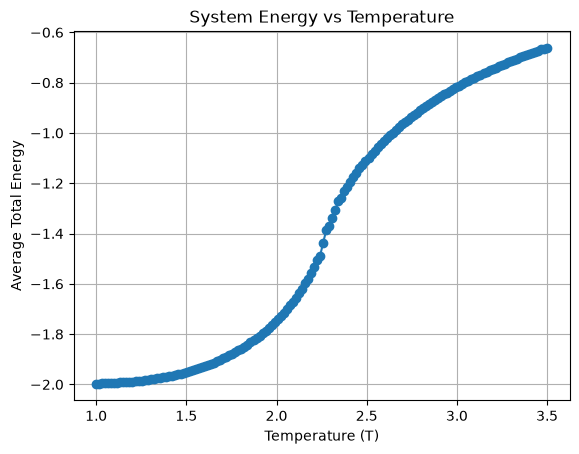

In [8]:
plt.plot(T_values, final_eng, marker='o')
plt.xlabel('Temperature (T)')
plt.ylabel('Average Total Energy')
plt.title('System Energy vs Temperature')
plt.grid(True)
plt.show()